# Plasma Potential Calculation

## Recreating figure 1 from NASA paper

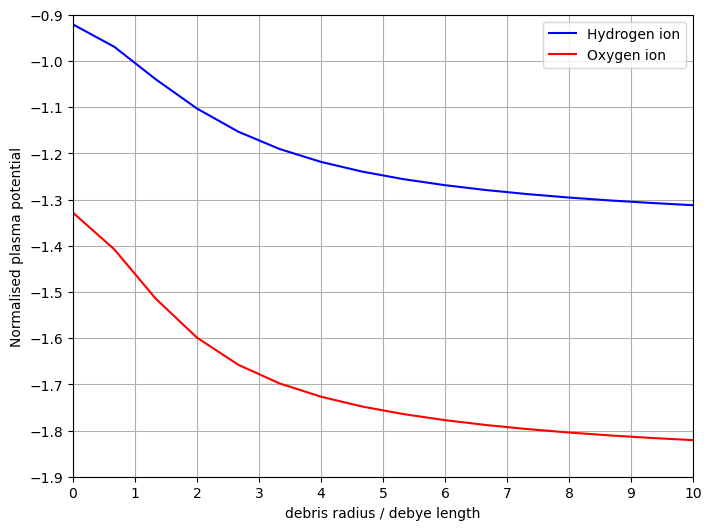

In [3]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def surface_potential_equation(x, mass_ratio, s, a):
    """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function """
    return np.exp(x) - np.sqrt(mass_ratio) * ((s/a)**2) * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))


#consants
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
debye_length = 1 # Example value for debye radius

r = debye_length # Distance from the debris surface the potnetial is felt too, which for plasma is the debye length, this is used to normalise the plasma potential

a_array = np.linspace( 1e-3, 10, 16) # Array of debris radii from 0.00001 to 10 in 16 steps

phi_ox= np.zeros(len(a_array))
phi_h = np.zeros(len(a_array))

# Calculate the normalised plasma potential for each debris radius
for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mo__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_ox[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential

for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mh__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_h[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential


# PLOTTING
plt.figure(figsize=(8, 6))
plt.grid()
plt.plot(a_array / debye_length, phi_h, label="Hydrogen ion", color="blue")
plt.plot(a_array/ debye_length, phi_ox, label="Oxygen ion", color="red")
plt.xlabel("debris radius / debye length")
plt.ylabel("Normalised plasma potential")
plt.xticks(np.arange(0, 11, 1))
plt.yticks(np.arange(-2, 1, 0.1))
plt.xlim(0, 10)
plt.ylim( -1.9,-0.9)
plt.legend()
plt.show()

### Functionisng the Normalised Plasma Potential Calculation & Validating against NASA paper values (Table 6)

In [4]:
from scipy.optimize import brentq
import numpy as np

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

# ========= Validation against NASA paper values (Table 6) =========
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

mass_ratio_o = __me__ / __mo__
mass_ratio_h = __me__ / __mh__

# values extracted from NASA paper Table 6 f

debris_diameters= [10e-2, 5e-2, 1e-2, 5e-3, 1e-3] # Debris diameters in meters
debye_lengths = [.83e-2, 1.38e-2, 4.36e-2, 23504e-2] # Debye lengths for Low LEO, Low LEO I, Low LEO II, and GEO respectively in meters

lowleo_phi_values = [-1.77, -1.68, -1.40, -1.35, -1.33]
lowleoi_phi_values = [-1.20, -1.08, -0.94, -0.93, -0.92]
lowleoii_phi_values = [-1.02, -0.96, -0.92, -0.92, -0.92]

debris_radii = [d/2 for d in debris_diameters] # Debris radii in meters

# Low LEO
print("=Normalised plasma potential calculations for Low LEO region (Oxygen)=:")
for a in debris_radii:
    phi_lowleo = normalised_plasma_potential(a, debye_lengths[0], mass_ratio_o)
    uncertainty = abs(phi_lowleo - lowleo_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleo:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO I
print("\n=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoi = normalised_plasma_potential(a, debye_lengths[1], mass_ratio_h)
    uncertainty = abs(phi_lowleoi - lowleoi_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoi:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO II
print("\n=Normalised plasma potential calculations for Low LEO II region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoii = normalised_plasma_potential(a, debye_lengths[2], mass_ratio_h)
    uncertainty = abs(phi_lowleoii - lowleoii_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoii:.3f}, uncertainty: {uncertainty:.3f}")

=Normalised plasma potential calculations for Low LEO region (Oxygen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.778, uncertainty: 0.008
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.680, uncertainty: 0.000
Debris radius: 5.0e-03 m, Normalised plasma potential: -1.398, uncertainty: 0.002
Debris radius: 2.5e-03 m, Normalised plasma potential: -1.353, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -1.330, uncertainty: 0.000

=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.204, uncertainty: 0.004
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.086, uncertainty: 0.006
Debris radius: 5.0e-03 m, Normalised plasma potential: -0.941, uncertainty: 0.001
Debris radius: 2.5e-03 m, Normalised plasma potential: -0.927, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -0.921, uncertainty: 0.001

=Normalised plasma potential c

calculating forcing term in low leo


Plotting.


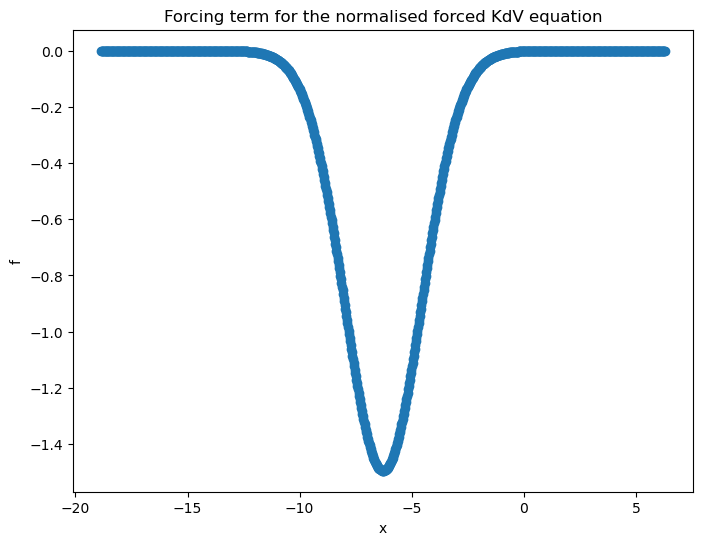

In [5]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((e - (vd * tau))/ G)**2)


a = 0.01 # Debris radius in m
L =  2*np.pi# size of the domain
vd = 0
N = 1024

tau = np.linspace(0, L, N)
xi = np.linspace(-3* L, L, N)

e = ( np.pi / L ) * (xi + L)

debye_length = .83e-2
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
mass_ratio_o = __me__ / __mo__


G = a / debye_length # Normalised forcing width
np_potential = normalised_plasma_potential(a, debye_length, mass_ratio_o)


print("Plotting.")

# 3D surface plot

f = forcing_term(np_potential, xi, 1, vd, G)

plt.figure(figsize=(8, 6))
plt.scatter(xi, f)
plt.xlabel('x')
plt.ylabel('f')
plt.title('Forcing term for the normalised forced KdV equation')
plt.show()

# Plasma solution simulation



## Functions

In [6]:
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df_ionosphere[region].to_numpy()
    properties =  df_ionosphere["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((xi - (vd * tau))/ G)**2)

def fkdv_exact_solution(a, x, K = 0.6124):
    return a / (np.cosh(K * x)**2)

def ck_solutions(last_sol, current_sol, alpha, beta, k, f, dt):
    """Use the Crank-Nicolson scheme to solve the normalised forced KdV equation on a non-periodic domain."""
    # pre-calculating coefficients
    _ck_beta = dt * beta * 1j * k**3 # removed s**3 term
    _ck_z = dt * 1j * k # removed s term

    # computing the rfft of u & f halfs the length of array which then is multipled by 1024 leng coefficents arrays because of k
    _ck_beta_fft = _ck_beta[:len(k)//2+1]  # Keep only first 513 elements
    _ck_z_fft = _ck_z[:len(k)//2+1]

    # Fourier transform of the last solution, current solution, and forcing term
    fft_last = rfft(last_sol)
    fft_current_sqrd = rfft(current_sol**2)
    fft_f = rfft(f)

    return irfft( ((1 - _ck_beta_fft)**-1) * ( (1 + _ck_beta_fft) * fft_last - alpha * _ck_z_fft * (fft_current_sqrd) + _ck_z_fft * fft_f ) )

## Imports & variables

In [7]:
import numpy as np
from numpy.fft import rfft, irfft
import pandas as pd
from numpy import pi, cos, linspace, arange
from scipy.fftpack import diff as psdiff
import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from scipy.optimize import brentq

# Upload the Ionosphere properties from the Excel file
df_ionosphere= pd.read_excel(r'Ionosphere prop.xltx')
display(df_ionosphere)

# Pulls the properties for the Low LEO region into a dictionary
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO")

# =============================== Inputs ================================

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458.0  # Speed of light in m/s
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

# Physical parameters
a = 0.01 # debris in m
alpha = 1.0051
beta = 0.4925

vd = 1.20 # Debris velocity in km/s
np_potential = None # Normalised plasma potential, if None, it will be automatically calculated.

# Simulation parameters
N = 1024 # number of discretised points in the domain (power of 2 for FFT speed)
L = 300.0 # size of the domain
G = a / (plasma_prop["Debye Length"] * 1e-2) # Normalised forcing width
dtau = 0.02# TU
tau_inital = 0.0  # TU
tau_final = 60.0 # TU
num_stablising_steps = 5 # Number of steps to stablise the solution before starting the main simulation

# Normlaised units
TU = (plasma_prop["Debye Length"] * 1e-2) / (plasma_prop["Ion Acoustic Velocity"] * 1e3) # Time unit in seconds
vd_norm = vd / (plasma_prop["Ion Acoustic Velocity"] * 1e3) # Normalised debris velocity

# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi= __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)

,Properties,Units,Low LEO,High LEO I,High LEO II,GEO
0,Altitude,km,700,1200,1400,35786
1,Latitude,deg,"0,50",0-55,0-55,0-90
2,Electron Density,cm^-3,200000,100000,10000,1
3,Electron Tempreture,eV,0.25,0.35,0.35,1000
4,Ion Species,NaN,O,H,H,OH
5,Ion Mass,proton mass,16,1,1,"16,1"
6,Debye Length,cm,0.83,1.38,4.36,23504
7,Debris Velocity Circular Orbit,km/s,7.51,7.26,7.16,3.08
8,Ion Acoustic Velocity,km/s,1.22,5.75,5.75,"77.43 , 309.73"


## Main
### Numerical simulation (starting from rest frame)

In [12]:
if __name__ == "__main__":
    # Defining mesh space & waven numbers
    xi = np.linspace(-L, L , N, endpoint=False)
    dxi = xi[1] - xi[0]
    k = 2*np.pi*np.fft.fftfreq(N, d=dxi)

    # Initialising the solution array and time array
    num_steps = int(abs((tau_inital + (dtau/10) * num_stablising_steps ) - tau_final)/dtau) + num_stablising_steps + 2
    time_array = np.zeros(num_steps)
    sol = np.zeros(((len(time_array) + 1),N))
    print(f"Number of time steps: {num_time_steps}")

    sol[0] = np.zeros(N) # Initial condition is set to the exact solution of the KdV equation
    sol[1] = np.zeros(N) # SWITCH THIS TO START FROM RESTFRAME OR ANALYTICAL SOLITON
    time_array[0] = tau_inital - dtau  # Intial time step is set to tau_inital - dtau to account for the first step being a special case

    step = 1
    current_time = tau_inital   # start
    while current_time <= tau_final:
        current_dtau = dtau

        if step <= num_stablising_steps: # Helps stablise pertubations caused by starting from rest frame.
            current_dtau = dtau/10

        forcing = forcing_term(np_potential, xi, current_time, vd_norm, G)
        sol[step + 1] = ck_solutions(last_sol=sol[step - 1],  # Propogate exact solution forward in time with CK scheme
                                     current_sol=sol[step],
                                     alpha=alpha,
                                     beta=beta,
                                     k=k,
                                     f=forcing,
                                     dt=current_dtau
                                     )

        if step % 1 == 0: # only prints every 10000 steps to avoid cluttering the output
            print(f"Time step: {step}, Time: {current_time:.2f} TU")
            print(f"Max value of solution: {np.max(sol[step + 1]):.4f}, Min value of solution: {np.min(sol[step + 1]):.4f}")

        time_array[step] = current_time

        step += 1
        current_time += current_dtau

    print("Simulation complete.")
    print(time_array[-1], sol[-1])

    numerical_sol = sol
    numerical_time_array = time_array

Number of time steps: 3004
Time step: 1, Time: 0.00 TU
Max value of solution: 0.0017, Min value of solution: -0.0017
Time step: 2, Time: 0.00 TU
Max value of solution: 0.0017, Min value of solution: -0.0017
Time step: 3, Time: 0.00 TU
Max value of solution: 0.0034, Min value of solution: -0.0034
Time step: 4, Time: 0.01 TU
Max value of solution: 0.0034, Min value of solution: -0.0034
Time step: 5, Time: 0.01 TU
Max value of solution: 0.0051, Min value of solution: -0.0051
Time step: 6, Time: 0.01 TU
Max value of solution: 0.0203, Min value of solution: -0.0214
Time step: 7, Time: 0.03 TU
Max value of solution: 0.0219, Min value of solution: -0.0233
Time step: 8, Time: 0.05 TU
Max value of solution: 0.0367, Min value of solution: -0.0412
Time step: 9, Time: 0.07 TU
Max value of solution: 0.0383, Min value of solution: -0.0433
Time step: 10, Time: 0.09 TU
Max value of solution: 0.0524, Min value of solution: -0.0624
Time step: 11, Time: 0.11 TU
Max value of solution: 0.0540, Min value of

### Analytical solution (initalise with analytical solution)

Number of time steps: 3004
Time step: 1, Time: 0.00 TU
Max value of solution: 0.0255, Min value of solution: -0.0113
Time step: 2, Time: 0.02 TU
Max value of solution: 0.0255, Min value of solution: -0.0113
Time step: 3, Time: 0.04 TU
Max value of solution: 0.0419, Min value of solution: -0.0306
Time step: 4, Time: 0.06 TU
Max value of solution: 0.0419, Min value of solution: -0.0306
Time step: 5, Time: 0.08 TU
Max value of solution: 0.0577, Min value of solution: -0.0513
Time step: 6, Time: 0.10 TU
Max value of solution: 0.0577, Min value of solution: -0.0513
Time step: 7, Time: 0.12 TU
Max value of solution: 0.0727, Min value of solution: -0.0726
Time step: 8, Time: 0.14 TU
Max value of solution: 0.0727, Min value of solution: -0.0725
Time step: 9, Time: 0.16 TU
Max value of solution: 0.0871, Min value of solution: -0.0936
Time step: 10, Time: 0.18 TU
Max value of solution: 0.0871, Min value of solution: -0.0934
Time step: 11, Time: 0.20 TU
Max value of solution: 0.1008, Min value of

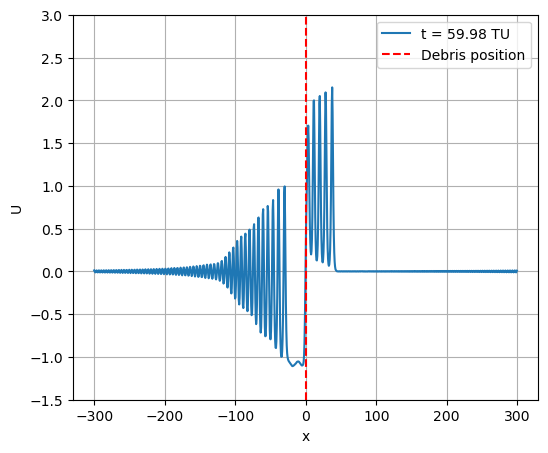

In [19]:
if __name__ == "__main__":
    # Defining mesh space & waven numbers
    xi = np.linspace(-L, L , N, endpoint=False)
    dxi = xi[1] - xi[0]
    k = 2*np.pi*np.fft.fftfreq(N, d=dxi)

    # Initialising the solution array and time array
    num_steps = int(abs(tau_inital - tau_final)/dtau) + 1
    time_array = np.zeros(num_steps)
    sol = np.zeros(((len(time_array) + 1),N))
    print(f"Number of time steps: {num_time_steps}")

    sol[0] = fkdv_exact_solution(a, xi) # Initial condition is set to the exact solution of the KdV equation
    sol[1] = fkdv_exact_solution(a, xi) # SWITCH THIS TO START FROM RESTFRAME OR ANALYTICAL SOLITON
    time_array[0] = tau_inital - dtau  # Intial time step is set to tau_inital - dtau to account for the first step being a special case

    step = 1
    current_time = tau_inital   # start
    while current_time <= tau_final:
        time_array[step] = current_time

        forcing = forcing_term(np_potential, xi, current_time, vd_norm, G)
        sol[step + 1] = ck_solutions(last_sol=sol[step - 1],  # Propogate exact solution forward in time with CK scheme
                                     current_sol=sol[step],
                                     alpha=alpha,
                                     beta=beta,
                                     k=k,
                                     f=forcing,
                                     dt=current_dtau
                                     )

        if step % 1 == 0: # only prints every 10000 steps to avoid cluttering the output
            print(f"Time step: {step}, Time: {current_time:.2f} TU")
            print(f"Max value of solution: {np.max(sol[step + 1]):.4f}, Min value of solution: {np.min(sol[step + 1]):.4f}")

        step += 1
        current_time += dtau

    print("Simulation complete.")
    print(time_array[-1], sol[-1])

    analytical_sol = sol
    analytical_time_array = time_array

    print("Plotting.")
# ---Display the final solution at the last time step---
for i in range(len(analytical_time_array)):
    if abs(analytical_time_array[i] - 60) < 1e-2:
        print(i)
        break
plt.figure(figsize=(6,5))
plt.plot(xi, analytical_sol[i], label=f"t = {analytical_time_array[i]:.2f} TU")
plt.axvline(vd_norm * analytical_time_array[i] , color='red', linestyle='--', label="Debris position")
plt.xlabel("x")
plt.ylabel("U")
plt.ylim(-1.5,3)
plt.legend()
plt.grid()
plt.show()

## Visualisation

### 2D Plot of U & X at some time

Plotting.


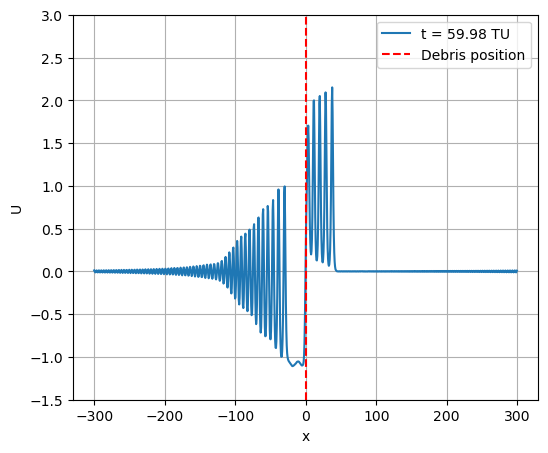

In [20]:
print("Plotting.")
# ---Display the final solution at the last time step---
for i in range(len(time_array)):
    if abs(time_array[i] - 60) < 1e-2:
        print(i)
        break
plt.figure(figsize=(6,5))
plt.plot(xi, sol[i], label=f"t = {time_array[i]:.2f} TU")
plt.axvline(vd_norm * time_array[i] , color='red', linestyle='--', label="Debris position")
plt.xlabel("x")
plt.ylabel("U")
plt.ylim(-1.5,3)
plt.legend()
plt.grid()
plt.show()

### 3D Surface Plot of U, X, & T

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

Xi, Tau = np.meshgrid(xi, time_array)  # Create meshgrid for plotting
fig = plt.figure(figsize=(6,5))
ax = plt.subplot(111, projection='3d')
surf = ax.plot_surface(Xi, Tau, sol, rstride=1000, cstride=1000, cmap='viridis', linewidth=0.1,antialiased=True)

ax.set_xlabel('x axis')
ax.set_ylabel('t axis')
ax.set_zlabel('U axis')

ax.view_init(elev=23, azim=100, roll=0)

plt.show()